# Reversible logic

Ordinary programs combine bits with logic: XOR, AND, OR. A quantum computer
can run these too, with one restriction. Every gate it runs can be undone: the
input can always be recovered from the output. Notebook 04 explains where
this restriction comes from; this notebook takes it as given and asks how to
live with it.

AND looks like a problem. Its output is 0 for three of its four inputs, so
the output alone cannot tell you which input you started with. This notebook
shows how to compute AND, and any other function of bits, with operations
that can be undone, and builds the three standard two- and three-bit gates
out of the one-bit operators of Notebook 01.

## Before you start

This notebook assumes [Notebook 00](00_Bits_and_Basis_States.ipynb)
(bitstrings with bit 0 on the right, the tensor product, the creation and
annihilation operators $a^\dagger$ and $a$, running circuits with the
Sampler) and [Notebook 01](01_One_Bit_Operators.ipynb) (outer products, the
projectors $n = |1\rangle\langle 1|$ and $\bar n = |0\rangle\langle 0|$,
completeness $n + \bar n = I$, and the Pauli operators $X = a + a^\dagger$ and
$Z = I - 2n$).

Quick check:

1. What are $n|1\rangle$ and $\bar n|1\rangle$?
2. Write the matrix of $X$.
3. Which four-component vector is $|10\rangle$?

Answers: $|1\rangle$ and the zero vector; $\begin{pmatrix}0&1\\1&0\end{pmatrix}$;
$(0, 0, 1, 0)^T$.

After this notebook you will be able to:

1. Write the matrix of an operation that acts on one bit of a register of
   several bits.
2. Build, from the set, clear, NOT and "is it 1?" operators, the operations
   "flip bit 1 if bit 0 is 1", "exchange two bits", and "flip bit 2 if bits 0
   and 1 are both 1", and check their truth tables.
3. Compute any function of bits, such as AND, with operations that can be
   undone, and clear any extra bits used along the way.

## Setup

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace

import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# _runtime.py (in ../scripts) decides where circuits run:
# the Aer simulator, plus IBM hardware if asked.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _runtime import get_targets

np.set_printoptions(precision=3, suppress=True)

SETTINGS = SimpleNamespace(
    shots=4096,                  # runs of each circuit
    precision=0.02,              # used from Notebook 09 on
    backend="ibm_rensselaer",
    name="default",              # saved IBM account name
    skip_hardware=True,          # set to False to also run on IBM hardware
    poll_interval=20,            # seconds between hardware status checks
)
targets = get_targets(SETTINGS)
print("Running on:", [t.label for t in targets])

Running on: ['aer']


## Operators on one bit of a register

Notebook 01 built operators for a single bit. In a register of two bits, how
do we write "apply $X$ to bit 1 and leave bit 0 alone"? Notebook 00 combined
the vectors of two bits with the tensor product. Operators combine the same
way.

The *tensor product of operators* $A \otimes B$ is the block matrix that
replaces each entry $A_{ij}$ of $A$ by the block $A_{ij}\,B$. For two
$2\times2$ matrices the result is $4\times4$:

$$A \otimes B = \begin{pmatrix} A_{00}\,B & A_{01}\,B \\ A_{10}\,B & A_{11}\,B \end{pmatrix}.$$

Its defining property is that it acts on a tensor product of vectors factor by
factor:

$$(A \otimes B)\,(|u\rangle \otimes |v\rangle) = A|u\rangle \otimes B|v\rangle.$$

In words: the left operator acts on the left bit and the right operator on
the right bit, each on its own. With the bit order of Notebook 00, the left
factor is bit 1 and the right factor is bit 0. The property follows from the
block form: $|u\rangle \otimes |v\rangle$ is the stack of blocks $u_j\,|v\rangle$,
so block row $i$ of $A \otimes B$ times it gives
$\sum_j A_{ij}\,u_j\,B|v\rangle = (A|u\rangle)_i\,B|v\rangle$, which is block
$i$ of $A|u\rangle \otimes B|v\rangle$.

Applying the property twice gives the *mixed-product rule*

$$(A \otimes B)(C \otimes D) = AC \otimes BD.$$

Both sides send every $|u\rangle \otimes |v\rangle$ to
$AC|u\rangle \otimes BD|v\rangle$. The basis bitstrings are vectors of this
form, and a matrix is fixed by what it does to the basis vectors (its
columns), so the two matrices are equal.

Writing $\otimes$ and identities everywhere gets long, so we use a subscript.
$A_k$ means the operator $A$ applied to bit $k$, with the identity on every
other bit. For two bits,

$$X_0 = I \otimes X, \qquad X_1 = X \otimes I, \qquad n_0\,X_1 = X \otimes n.$$

Two operators *commute* when $AB = BA$, so the order in which they act does
not matter. Operators on different bits act on different factors, and they
always commute. By the mixed-product rule,
$A_0\,B_1 = (I \otimes A)(B \otimes I) = B \otimes A$, and
$B_1\,A_0 = (B \otimes I)(I \otimes A) = B \otimes A$ as well; the third
example above is the case $A = n$, $B = X$. Operators on the same bit
multiply as in Notebook 01, for example $n_0\,n_0 = n_0$.

### Example 1: NOT on bit 1 of $|01\rangle$

**Problem.** Compute $X_1|01\rangle$, first factor by factor and then as a
$4\times4$ matrix.

**Plan.** Write $X_1 = X \otimes I$ and $|01\rangle = |0\rangle \otimes |1\rangle$,
apply the defining property, then check with `np.kron`.

**Solution.**

**Subgoal 1: factor by factor.**

1. Bit 1 is the left factor: $X_1|01\rangle = (X \otimes I)(|0\rangle \otimes |1\rangle)$.
2. Apply the defining property: $= X|0\rangle \otimes I|1\rangle$.
3. Use $X|0\rangle = |1\rangle$ and $I|1\rangle = |1\rangle$: $= |1\rangle \otimes |1\rangle = |11\rangle$.

**Subgoal 2: as a matrix.**

4. Replace each entry of $X$ by that entry times $I$:
   $X \otimes I = \begin{pmatrix}0 & I\\ I & 0\end{pmatrix} = \begin{pmatrix}0&0&1&0\\0&0&0&1\\1&0&0&0\\0&1&0&0\end{pmatrix}$.
5. $|01\rangle = (0, 1, 0, 0)^T$ picks out column 1 of the matrix, which is
   $(0, 0, 0, 1)^T = |11\rangle$.

**Check.** NOT on bit 1 should change the left character only: $01 \to 11$.
Both methods agree.

**Takeaway.** $A_k$ acts on bit $k$ alone. Its matrix is a tensor product
with $A$ in the position of bit $k$, counting from the right, and $I$
everywhere else.

In [2]:
ket0, ket1 = np.array([1, 0]), np.array([0, 1])
a = np.outer(ket0, ket1)          # |0><1|
a_dag = a.T                       # |1><0|
n, n_bar = a_dag @ a, a @ a_dag
I = np.eye(2, dtype=int)
X = a + a_dag

X_1 = np.kron(X, I)               # bit 1 is the left factor
ket_01 = np.kron(ket0, ket1)
print("X_1 =\n", X_1)
print("X_1 |01> =", X_1 @ ket_01, "  |11> =", np.kron(ket1, ket1))

X_1 =
 [[0 0 1 0]
 [0 0 0 1]
 [1 0 0 0]
 [0 1 0 0]]
X_1 |01> = [0 0 0 1]   |11> = [0 0 0 1]


**Check.** Write $X_0$ for two bits as a tensor product, and find $X_0|01\rangle$.

## Reversible functions and permutation matrices

A function on bitstrings is *reversible* if every output comes from exactly
one input. Then the input can always be recovered from the output, so the
function can be undone. NOT is reversible. AND is not: three of its four
inputs give the output 0.

What does a reversible function look like as an operator? It sends each
bitstring to one bitstring, and no two bitstrings to the same one. So each
column of its matrix (what it does to one input) has a single 1, and each row
(where one output comes from) has a single 1. A square matrix of 0s and 1s
with exactly one 1 in every row and every column is a *permutation matrix*.
In words: a permutation matrix rearranges the bitstrings without merging any.
Every reversible function on $n$ bits is a $2^n \times 2^n$ permutation
matrix, and its inverse is its transpose. To see why, call the matrix $M$.
Entry $(j, k)$ of $M^T M$ is column $j$ of $M$ times column $k$. Each column
is a basis bitstring, and no two columns are the same bitstring (each row has
only one 1), so this product is 1 when $j = k$ and 0 otherwise: $M^T M = I$.

A non-example is the "set to 0" operator $R = \bar n + a = \begin{pmatrix}1&1\\0&0\end{pmatrix}$
from Notebook 01, Exercise 3. Its first row has two 1s, because two inputs go
to $|0\rangle$, and it has no inverse.

The rest of this notebook builds permutation matrices out of the operators of
Notebook 01. The tool is completeness, $I = \bar n + n$, used to split an
operation into "what to do when a bit is 0" and "what to do when it is 1".

**Check.** Is $Z$ a permutation matrix? Is the zero matrix?

## Controlled-NOT: XOR that can be undone

XOR of two bits has the same problem as AND: two outputs, four inputs. The
fix is to keep one of the inputs. The operation $(c, t) \to (c,\, t \oplus c)$,
where $\oplus$ is XOR, keeps $c$ and replaces $t$ by $t \oplus c$. Given the
output, $c$ is still there, and $t = (t \oplus c) \oplus c$ can be recovered.

The *controlled-NOT* gate, written CX, does exactly this: it flips a *target*
bit when a *control* bit is 1. In words: "if the control is 1, apply $X$ to
the target". Qiskit writes it `circuit.cx(control, target)`.

### Example 2: CX from the projectors

**Problem.** Write CX with control bit 0 and target bit 1 in terms of $n_0$,
$\bar n_0$ and $X_1$, compute its $4\times4$ matrix, and check it on all four
inputs.

**Plan.** Split the identity with completeness on the control bit, put $X_1$
on the "control is 1" part, then build the matrix with tensor products.

**Solution.**

**Subgoal 1: write the operator.**

1. Completeness on bit 0: $I = \bar n_0 + n_0$. Every input is in exactly one
   of the two parts: bit 0 is 0 or it is 1.
2. When bit 0 is 0, do nothing: the part $\bar n_0$ stays as it is.
3. When bit 0 is 1, flip bit 1: multiply the part $n_0$ by $X_1$.
4. Add the two parts: $\mathrm{CX} = \bar n_0 + n_0\,X_1$.

**Subgoal 2: build the matrix.**

5. Bit 0 is the right factor: $\bar n_0 = I \otimes \bar n$ and
   $n_0\,X_1 = X \otimes n$.
6. $I \otimes \bar n$ puts $\bar n = \mathrm{diag}(1, 0)$ in both diagonal
   blocks: $\mathrm{diag}(1, 0, 1, 0)$.
7. $X \otimes n$ puts $n$ in the two off-diagonal blocks: its only 1s are in
   (row 1, column 3) and (row 3, column 1).
8. Add: $\mathrm{CX} = \begin{pmatrix}1&0&0&0\\0&0&0&1\\0&0&1&0\\0&1&0&0\end{pmatrix}$.

**Subgoal 3: check all inputs.**

9. Read each column as the output for one input $|x_1 x_0\rangle$: column 0
   gives $|00\rangle \to |00\rangle$, column 1 gives $|01\rangle \to |11\rangle$,
   column 2 gives $|10\rangle \to |10\rangle$, column 3 gives
   $|11\rangle \to |01\rangle$.

**Check.** In each case bit 0 is unchanged and bit 1 becomes $x_1 \oplus x_0$.
The matrix has one 1 in every row and column, so it is a permutation matrix.

**Self-explanation prompt.** In step 3, why can we multiply $n_0$ by $X_1$ in
either order? **Answer.** They act on different bits, so they commute.

**Takeaway.** "If bit $c$ is 1, apply $U$ to the others" is the operator
$\bar n_c + n_c\,U$. Completeness turns a condition into a sum.

In [3]:
CX = np.kron(I, n_bar) + np.kron(X, n)          # n_bar_0 + n_0 X_1
circuit = QuantumCircuit(2)
circuit.cx(0, 1)
print("CX =\n", CX)
print("matches Qiskit's cx(0, 1):", np.allclose(Operator(circuit).data, CX))
for x in range(4):
    out = int(np.argmax(CX[:, x]))
    print(f"  |{x:02b}> -> |{out:02b}>")

CX =
 [[1 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 1 0 0]]
matches Qiskit's cx(0, 1): True
  |00> -> |00>
  |01> -> |11>
  |10> -> |10>
  |11> -> |01>


**Check.** What does CX with control 0 and target 1 do to $|10\rangle$, and
why?

## SWAP: exchanging two bits

The operation that exchanges the values of two bits is reversible: doing it
twice restores the input. We build it from the four possible inputs.

### Example 3: SWAP from set, clear and the projectors

**Problem.** Write the SWAP of bits 0 and 1 in terms of $a$, $a^\dagger$, $n$
and $\bar n$, and check it against Qiskit.

**Plan.** Handle each of the four inputs $|x_1 x_0\rangle$ separately with a
projector, then add the pieces.

**Solution.**

**Subgoal 1: inputs whose bits are equal.**

1. For $|00\rangle$ and $|11\rangle$, exchanging the bits changes nothing.
2. The projector onto $|00\rangle$ is $\bar n_0\,\bar n_1$ and onto
   $|11\rangle$ is $n_0\,n_1$. These parts stay as they are.

**Subgoal 2: inputs whose bits differ.**

3. For $|01\rangle$ (bit 0 is 1, bit 1 is 0) the output is $|10\rangle$:
   clear bit 0 and set bit 1. That is $a_1^\dagger\,a_0$. On any other input,
   $a_0$ or $a_1^\dagger$ gives the zero vector, so this term acts only on
   $|01\rangle$.
4. For $|10\rangle$ the output is $|01\rangle$: clear bit 1 and set bit 0,
   $a_0^\dagger\,a_1$.

**Subgoal 3: add the parts.**

5. $\mathrm{SWAP} = \bar n_0\,\bar n_1 + n_0\,n_1 + a_1^\dagger a_0 + a_0^\dagger a_1$.

**Check.** The code below compares this sum with Qiskit's `swap` gate. A
second check: SWAP should equal three CX gates with alternating control,
$\mathrm{CX}_{0\to1}\,\mathrm{CX}_{1\to0}\,\mathrm{CX}_{0\to1}$.

**Takeaway.** The last two terms move a 1 from one bit to the other. A term
of the form $a_j^\dagger a_k$, "clear bit $k$ and set bit $j$", is a
*hopping term*. Hopping terms return in Unit 3, where the hydrogen-molecule
notebook uses them to move an electron from one place in the molecule to
another.

In [4]:
SWAP = (np.kron(n_bar, n_bar) + np.kron(n, n)
        + np.kron(a_dag, a)        # a_1^dagger a_0: bit 1 is the left factor
        + np.kron(a, a_dag))       # a_1 a_0^dagger = a_0^dagger a_1
circuit = QuantumCircuit(2)
circuit.swap(0, 1)
print("SWAP =\n", SWAP)
print("matches Qiskit's swap:", np.allclose(Operator(circuit).data, SWAP))

CX_10 = np.kron(n_bar, I) + np.kron(n, X)        # control 1, target 0
print("CX_01 CX_10 CX_01 == SWAP:", np.array_equal(CX @ CX_10 @ CX, SWAP))

SWAP =
 [[1 0 0 0]
 [0 0 1 0]
 [0 1 0 0]
 [0 0 0 1]]
matches Qiskit's swap: True
CX_01 CX_10 CX_01 == SWAP: True


**Check.** Which terms of SWAP act on $|11\rangle$, and what do the hopping
terms give there?

## The Toffoli gate: AND that can be undone

CX keeps its control and XORs it into the target. The same idea works for
AND. From here on we write the logic operations as symbols: $x \wedge y$ is
AND, $x \vee y$ is OR, and $\lnot x$ is NOT, which for a bit equals $1 - x$.
Keep both inputs and XOR their AND into a third bit,
$(c_0, c_1, t) \to (c_0,\, c_1,\, t \oplus (c_0 \wedge c_1))$. If the third bit
starts at 0, it ends holding $c_0 \wedge c_1$. The inputs are still there, so
the operation can be undone.

This is the controlled-controlled-NOT, written CCX, or the *Toffoli gate*
after Tommaso Toffoli: flip the target when both controls are 1. Qiskit
writes it `circuit.ccx(control0, control1, target)`.

### Example 4: CCX from the projectors

**Problem.** Write CCX with controls 0 and 1 and target 2 in terms of $n_0$,
$n_1$ and $X_2$, and check that bit 2 becomes $t \oplus (x_0 \wedge x_1)$.

**Plan.** Use the projector onto "both controls are 1" and its complement in
place of $n$ and $\bar n$, as in Example 2.

**Solution.**

**Subgoal 1: find the projector for the condition.**

1. $n_0\,n_1$ keeps an input only when bit 0 is 1 and bit 1 is 1:
   $n_0 n_1 |x\rangle = x_0 x_1 |x\rangle$, and $x_0 x_1 = x_0 \wedge x_1$
   for bits.
2. Its complement is $I - n_0\,n_1$, which keeps every other input. The two
   add to $I$, a completeness relation for this condition.

**Subgoal 2: write the operator.**

3. When the condition fails, do nothing: keep $I - n_0 n_1$.
4. When it holds, flip bit 2: $n_0 n_1 X_2$.
5. Add: $\mathrm{CCX} = I - n_0 n_1 + n_0 n_1 X_2$.

**Check.** The code compares the sum with Qiskit's `ccx` and prints the truth
table for the four inputs with $t = 0$. Bit 2 should end as
$x_0 \wedge x_1$: 1 only for $|011\rangle$.

**Takeaway.** Any condition on the controls that has a projector $P$ gives a
controlled gate $I - P + P\,U$, provided $U$ acts only on bits that the
condition does not test. Then $P$ and $U$ act on different bits and commute,
so $U$ cannot change whether the condition holds. For a single control,
$P = n_c$ and $I - P = \bar n_c$, which is Example 2.

The code below, and later code in this unit, works with the integer value
$x$ of a bitstring and Python's bitwise operators, which act on the binary
digits of integers: `x & 1` is bit 0 of $x$, `x >> k` shifts $x$ right by $k$
places (so `(x >> k) & 1` is bit $k$), `x << k` shifts left, and `x ^ y` and
`x | y` are the bitwise XOR and OR.

In [5]:
def on_bit(op, k, num_bits):
    """Matrix of a one-bit operator on bit k of a register.

    Bit 0 is the rightmost factor of the Kronecker product.
    """
    factors = [op if j == k else I for j in reversed(range(num_bits))]
    matrix = np.array([[1]])
    for f in factors:
        matrix = np.kron(matrix, f)
    return matrix


n0, n1, X2 = on_bit(n, 0, 3), on_bit(n, 1, 3), on_bit(X, 2, 3)
CCX = np.eye(8, dtype=int) - n0 @ n1 + n0 @ n1 @ X2
circuit = QuantumCircuit(3)
circuit.ccx(0, 1, 2)
print("matches Qiskit's ccx(0, 1, 2):", np.allclose(Operator(circuit).data, CCX))
for x in range(4):                 # inputs with bit 2 (the target) equal to 0
    out = int(np.argmax(CCX[:, x]))
    x0_and_x1 = (x & 1) & (x >> 1)
    print(f"  |{x:03b}> -> |{out:03b}>   bit 2 = {out >> 2}, x0 AND x1 = {x0_and_x1}")

matches Qiskit's ccx(0, 1, 2): True
  |000> -> |000>   bit 2 = 0, x0 AND x1 = 0
  |001> -> |001>   bit 2 = 0, x0 AND x1 = 0
  |010> -> |010>   bit 2 = 0, x0 AND x1 = 0
  |011> -> |111>   bit 2 = 1, x0 AND x1 = 1


A common mistake is to think that AND cannot run on a computer whose
operations must all be undone, because AND throws information away. That is
wrong: CCX computes AND into a third bit and keeps both inputs, so nothing is
thrown away. The idea is tempting because AND, as a function from two bits to
one, really is irreversible. The reversible version changes the question:
instead of replacing the inputs with the answer, it writes the answer next to
them.

**Check.** What does CCX do to $|111\rangle$?

## Oracles and uncomputation

CCX shows the general method. To compute a function $f$ that takes a
bitstring $x$ and returns one bit, add one extra bit, called an *ancilla*,
that starts at 0 and receives the answer. The operation

$$U_f:\; (x,\, y) \to (x,\, y \oplus f(x))$$

keeps the input $x$ and XORs $f(x)$ into the ancilla $y$. It is reversible for
every $f$, because $x$ is kept and $y$ can be recovered as
$(y \oplus f(x)) \oplus f(x)$. Here the label $x$ inside a ket stands for a
whole bitstring of several bits, and $|y\,x\rangle$ is the bitstring with
$y$ written to the left of the bits of $x$. With the ancilla as the
highest-numbered bit, in ket form $U_f\,|y\,x\rangle = |(y \oplus f(x))\,x\rangle$.
An operation of this form is an *oracle* for $f$. Unit 2 writes the same
operation as $U_f|x\rangle|y\rangle = |x\rangle|y \oplus f(x)\rangle$, with
the input first, the order most textbooks use. Two kets written side by side
mean their tensor product, $|x\rangle|y\rangle = |x\rangle \otimes |y\rangle$;
it is the same operation with the factors listed in the other order.

Applying $U_f$ twice gives $y \oplus f(x) \oplus f(x) = y$, so $U_f$ is its
own inverse. This gives a way to clean up. A long calculation often needs
scratch bits for intermediate results; at the end, running the steps that
produced them again, in reverse order, returns every scratch bit to 0. This
is *uncomputation*.

### Example 5: an oracle for $f(x_1, x_0) = x_1 \wedge \lnot x_0$

**Problem.** Build an oracle for $f(x_1, x_0) = x_1 \wedge \lnot x_0$, which is
1 only for the input $x_1 x_0 = 10$, with the input on bits 0 and 1 and the
ancilla on bit 2. Check its truth table and that applying it twice does
nothing.

**Plan.** CCX computes $x_0 \wedge x_1$. To get $\lnot x_0$ in place of
$x_0$, flip bit 0 before the CCX and flip it back afterward.

**Solution.**

**Subgoal 1: build the circuit.**

1. Apply $X_0$: bit 0 now holds $\lnot x_0$.
2. Apply CCX with controls 0 and 1 and target 2: bit 2 becomes
   $y \oplus (\lnot x_0 \wedge x_1)$.
3. Apply $X_0$ again: bit 0 is back to $x_0$, because $X^2 = I$.

**Subgoal 2: check the truth table.**

4. With $y = 0$, bit 2 ends as $x_1 \wedge \lnot x_0$: 1 for the input
   $|010\rangle$ and 0 for $|000\rangle$, $|001\rangle$, $|011\rangle$.

**Subgoal 3: check that it undoes itself.**

5. The circuit is $X_0\,\mathrm{CCX}\,X_0$. Its square is
   $X_0\,\mathrm{CCX}\,X_0\,X_0\,\mathrm{CCX}\,X_0 = X_0\,\mathrm{CCX}^2\,X_0 = X_0\,X_0 = I$,
   using $X_0^2 = I$ and $\mathrm{CCX}^2 = I$.

**Check.** The code builds the circuit and compares its truth table with $f$
for all eight inputs, including those with $y = 1$, where bit 2 should end as
$1 \oplus f(x)$.

**Takeaway.** NOT gates around a control turn "is 1" into "is 0". The same
idea builds an oracle for any function of a few bits. For each input pattern
with $f(x) = 1$, flip the ancilla under the condition "the input equals this
pattern", with NOT gates around the controls that must be 0, exactly as in
this example. Each such flip acts on one input only, so together they XOR
$f(x)$ into the ancilla. With two input bits each flip is one CCX; with more
input bits the condition is built from several CCX gates and a scratch bit,
as Exercise 4 does for three bits.

In [6]:
def oracle_circuit():
    """U_f for f(x1, x0) = x1 AND NOT x0; input on qubits 0, 1, ancilla on qubit 2."""
    circuit = QuantumCircuit(3, name="U_f")
    circuit.x(0)
    circuit.ccx(0, 1, 2)
    circuit.x(0)
    return circuit


def f(x):
    x0, x1 = x & 1, (x >> 1) & 1
    return x1 & (1 - x0)


U_f = Operator(oracle_circuit()).data.real
for x in range(8):
    out = int(np.argmax(U_f[:, x]))
    y, inputs = x >> 2, x & 0b11
    print(f"  |{x:03b}> -> |{out:03b}>   expected bit 2 = {y ^ f(inputs)}")
print("U_f @ U_f == I:", np.allclose(U_f @ U_f, np.eye(8)))

  |000> -> |000>   expected bit 2 = 0
  |001> -> |001>   expected bit 2 = 0
  |010> -> |110>   expected bit 2 = 1
  |011> -> |011>   expected bit 2 = 0
  |100> -> |100>   expected bit 2 = 1
  |101> -> |101>   expected bit 2 = 1
  |110> -> |010>   expected bit 2 = 0
  |111> -> |111>   expected bit 2 = 1
U_f @ U_f == I: True


A second common mistake is to think that a reversible computer must keep
every intermediate result forever, so its memory fills with scratch bits.
That is wrong: because each step can be undone, the scratch bits can be
returned to 0 by uncomputation once the final answer is copied out. Exercise 4
does this for the AND of three bits. The idea is tempting because erasing a
bit (setting it to 0 whatever its value) is not reversible; uncomputation
avoids erasing by running the computation backward instead.

Unit 2 starts from this oracle. Its Deutsch-Jozsa, Bernstein-Vazirani and
Simon notebooks each hand a quantum computer an oracle $U_f$ built from CX,
CCX and NOT gates, and ask what can be learned about $f$ from it.

**Check.** An oracle for $f(x_1, x_0) = x_0 \oplus x_1$ needs no CCX. Which
two gates build it?

## The experiment: truth tables on a quantum computer

We run CX, SWAP, CCX and the oracle of Example 5 on every input and compare
the measured truth tables with the ideal ones.

### Encoding

Each input bitstring is prepared with NOT gates, as in Notebook 00.

In [7]:
def prepare(bitstring):
    """Circuit that prepares |bitstring> (bit 0 is the rightmost character)."""
    num_bits = len(bitstring)
    circuit = QuantumCircuit(num_bits)
    for k in range(num_bits):
        if bitstring[-1 - k] == "1":
            circuit.x(k)
    return circuit

### Operator

Each gate, as a circuit, and the classical rule it should follow. The rule
works on the integer value of the bitstring, with bit $k$ in position $k$.

Two Qiskit methods join circuits and add measurements. `a.compose(b)`
returns a new circuit that runs `a` and then `b`; with `inplace=True` it adds
`b` to the end of `a` itself instead. `measure_all()` adds one classical bit
per qubit, in a register named `meas`, and measures every qubit into it,
which is what the earlier notebooks did by hand. It also draws a dashed
vertical line before the measurements. That line is a barrier; it changes
nothing in this notebook, and Notebook 04 explains what it is for.

24 circuits


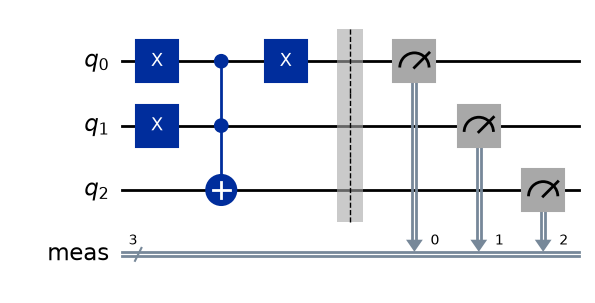

In [8]:
def gate_circuit(name):
    circuit = QuantumCircuit(3 if name in ("CCX", "oracle") else 2)
    if name == "CX":
        circuit.cx(0, 1)
    elif name == "SWAP":
        circuit.swap(0, 1)
    elif name == "CCX":
        circuit.ccx(0, 1, 2)
    else:
        circuit.compose(oracle_circuit(), inplace=True)
    return circuit


def ideal_output(name, x):
    x0, x1 = x & 1, (x >> 1) & 1
    if name == "CX":
        return x ^ (x0 << 1)                     # bit 1 becomes x1 XOR x0
    if name == "SWAP":
        return (x0 << 1) | x1
    if name == "CCX":
        return x ^ ((x0 & x1) << 2)              # bit 2 becomes x2 XOR (x0 AND x1)
    return x ^ (f(x & 0b11) << 2)                # oracle


GATE_NAMES = ["CX", "SWAP", "CCX", "oracle"]
circuits, expected = {}, {}
for name in GATE_NAMES:
    num_bits = gate_circuit(name).num_qubits
    for x in range(2**num_bits):
        bitstring = format(x, f"0{num_bits}b")
        circuit = prepare(bitstring).compose(gate_circuit(name))
        # Adds a classical register named "meas".
        circuit.measure_all()
        circuits[(name, bitstring)] = circuit
        expected[(name, bitstring)] = format(ideal_output(name, x), f"0{num_bits}b")

print(len(circuits), "circuits")
circuits[("oracle", "010")].draw("mpl")

How many gates does each operation cost? A common reference is to rewrite
every circuit using only CX and one-qubit gates. The next cell does that for
the bare gates, with no input preparation. Instead of a backend, it gives the
pass manager a list `basis_gates`, the only gates the transpiler may use:
here CX, $X$, and two more one-qubit gates, `rz` and `sx`, that IBM hardware
runs natively. Notebook 07 defines `rz` and `sx`; for now they are counted
as one-qubit gates.

In [9]:
reference = generate_preset_pass_manager(
    basis_gates=["cx", "rz", "sx", "x"], optimization_level=1
)
for name in GATE_NAMES:
    ops = dict(reference.run(gate_circuit(name)).count_ops())
    print(f"{name:6s} uses {ops.get('cx', 0)} CX gates   (all gates: {ops})")

CX     uses 1 CX gates   (all gates: {'cx': 1})
SWAP   uses 3 CX gates   (all gates: {'cx': 3})
CCX    uses 6 CX gates   (all gates: {'rz': 10, 'cx': 6, 'sx': 2})
oracle uses 6 CX gates   (all gates: {'rz': 10, 'cx': 6, 'x': 2, 'sx': 2})


The transpiler writes SWAP with 3 CX gates, the construction Example 3
checked. It writes CCX with 6, so on hardware a Toffoli gate costs several
times as much as a CX.

### Execution

All the circuits go into one job.

In [10]:
isa_circuits = {}
for target in targets:
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    isa_circuits[target.label] = {
        key: pass_manager.run(c) for key, c in circuits.items()
    }

pubs = {
    label: [(isa,) for isa in group.values()]
    for label, group in isa_circuits.items()
}

results = {}
for target in targets:
    job = target.sampler.run(pubs[target.label], shots=SETTINGS.shots)
    # wait() returns None if a hardware job failed or you stopped waiting.
    results[target.label] = target.wait(job)

### Analysis

For each gate we print the truth table: the input, the most frequent measured
output, the ideal output, and the fraction of shots on the ideal output.

In [11]:
for label, result in results.items():
    if result is None:
        continue
    print(f"{label}, {SETTINGS.shots} shots per input")
    for name in GATE_NAMES:
        print(f"  {name}")
        for key, pub_result in zip(circuits, result):
            if key[0] != name:
                continue
            counts = pub_result.data.meas.get_counts()
            measured = max(counts, key=counts.get)
            fraction = counts.get(expected[key], 0) / SETTINGS.shots
            print(
                f"    in {key[1]} -> measured {measured}, ideal {expected[key]},"
                f" fraction {fraction:.3f}"
            )

aer, 4096 shots per input
  CX
    in 00 -> measured 00, ideal 00, fraction 1.000
    in 01 -> measured 11, ideal 11, fraction 1.000
    in 10 -> measured 10, ideal 10, fraction 1.000
    in 11 -> measured 01, ideal 01, fraction 1.000
  SWAP
    in 00 -> measured 00, ideal 00, fraction 1.000
    in 01 -> measured 10, ideal 10, fraction 1.000
    in 10 -> measured 01, ideal 01, fraction 1.000
    in 11 -> measured 11, ideal 11, fraction 1.000
  CCX
    in 000 -> measured 000, ideal 000, fraction 1.000
    in 001 -> measured 001, ideal 001, fraction 1.000
    in 010 -> measured 010, ideal 010, fraction 1.000
    in 011 -> measured 111, ideal 111, fraction 1.000
    in 100 -> measured 100, ideal 100, fraction 1.000
    in 101 -> measured 101, ideal 101, fraction 1.000
    in 110 -> measured 110, ideal 110, fraction 1.000
    in 111 -> measured 011, ideal 011, fraction 1.000
  oracle
    in 000 -> measured 000, ideal 000, fraction 1.000
    in 001 -> measured 001, ideal 001, fraction 1.000

On the simulator every input lands on its ideal output with fraction 1.000:
the operators built from $a$, $a^\dagger$, $n$ and $\bar n$ match the gates.

## Exercises

1. Write CX with control 1 and target 0 as $\bar n_1 + n_1 X_0$. Build its
   matrix with `np.kron` and list what it does to each of the four inputs.
2. Show that $\mathrm{CX}^2 = I$ for $\mathrm{CX} = \bar n_0 + n_0 X_1$, using
   $\bar n_0^2 = \bar n_0$, $n_0^2 = n_0$, $n_0\,\bar n_0 = 0$, $X_1^2 = I$, and
   the fact that operators on different bits commute.
3. Build an oracle for $f(x_1, x_0) = x_0 \vee x_1$ (OR) from NOT and CCX.
   (Hint: $x_0 \vee x_1 = \lnot(\lnot x_0 \wedge \lnot x_1)$.) Check its truth
   table with `Operator`.
4. Compute $x_0 \wedge x_1 \wedge x_2$ into bit 4, using bit 3 as a scratch
   bit: CCX(0, 1 → 3), then CCX(3, 2 → 4), then CCX(0, 1 → 3) again. Check
   on all eight inputs (bits 3 and 4 starting at 0) that bit 4 holds the AND
   of the three inputs and bit 3 ends at 0. Which step is the uncomputation?
5. (Uses Notebook 01.) $Z_1 Z_0$ multiplies $|x_1 x_0\rangle$ by a sign. Find
   the sign for each of the four inputs from $Z|x\rangle = (1 - 2x)|x\rangle$,
   and write it in terms of $x_0 \oplus x_1$.
6. True or false: a computer whose every operation can be undone cannot
   compute AND, because AND throws away information. Give the reason.
7. (hardware) Set `skip_hardware=False` in the Setup cell and run the
   notebook. Compare the average fraction on the ideal output for CX, SWAP
   and CCX. Then print `dict(isa_circuits["ibm_rensselaer"][("CCX", "011")].count_ops())`
   (use the backend's label if it differs) to see which two-qubit gate the
   machine uses natively and how many of them each operation needs. Does the
   ranking of the fractions follow the number of two-qubit gates?

## What you can now do

1. Write $A_k$, an operator on bit $k$ of a register, as a tensor product,
   and use the fact that operators on different bits commute.
2. Build CX $= \bar n_0 + n_0 X_1$, SWAP from projectors and hopping terms,
   and CCX $= I - n_0 n_1 + n_0 n_1 X_2$, and check their truth tables.
3. Write any function of bits as an oracle $U_f$, and clear scratch bits by
   uncomputation.

## Solutions

**Check, one bit of a register.** $X_0 = I \otimes X$, and
$X_0|01\rangle = I|0\rangle \otimes X|1\rangle = |0\rangle \otimes |0\rangle = |00\rangle$.

**Check, permutation matrices.** $Z = \mathrm{diag}(1, -1)$ is not: it
contains $-1$. (It does send each bitstring to itself up to a sign, which is
why it behaved like $I$ in the counts of Notebook 01.) The zero matrix is
not: its rows have no 1.

**Check, CX.** $|10\rangle$ has bit 0 equal to 0, so the control is 0 and
nothing happens: $|10\rangle \to |10\rangle$.

**Check, SWAP.** Only $n_0 n_1$ keeps $|11\rangle$. The hopping terms both
give the zero vector there, because $a_1^\dagger$ cannot set bit 1 when it is
already 1, and $a_0^\dagger$ cannot set bit 0.

**Check, Toffoli.** Both controls are 1, so the target flips:
$|111\rangle \to |011\rangle$.

**Check, oracles.** Two CX gates, one from each input bit to the ancilla:
CX(0 → 2) then CX(1 → 2). The ancilla ends as $y \oplus x_0 \oplus x_1$.

**Exercise 1.** $\bar n_1 + n_1 X_0 = \bar n \otimes I + n \otimes X$.
`np.kron(n_bar, I) + np.kron(n, X)` gives

$$\begin{pmatrix}1&0&0&0\\0&1&0&0\\0&0&0&1\\0&0&1&0\end{pmatrix}.$$

Reading the columns: $|00\rangle \to |00\rangle$, $|01\rangle \to |01\rangle$,
$|10\rangle \to |11\rangle$, $|11\rangle \to |10\rangle$. Bit 0 flips exactly
when bit 1 is 1.

**Exercise 2.** Expand, keeping the order of each product:
$(\bar n_0 + n_0 X_1)^2 = \bar n_0^2 + \bar n_0 n_0 X_1 + n_0 X_1 \bar n_0 + n_0 X_1 n_0 X_1$.
The first term is $\bar n_0$. The second is 0 because $\bar n_0 n_0 = 0$. In
the third, move $X_1$ past $\bar n_0$ (different bits): $n_0 \bar n_0 X_1 = 0$.
In the fourth, move $X_1$ past $n_0$: $n_0^2 X_1^2 = n_0$. The sum is
$\bar n_0 + n_0 = I$.

**Exercise 3.** Flip both inputs, CCX into the ancilla, flip the ancilla,
flip both inputs back:

```python
c = QuantumCircuit(3)
c.x([0, 1])
c.ccx(0, 1, 2)
c.x(2)
c.x([0, 1])
```

Given a list of qubits, `c.x([0, 1])` applies $X$ to each qubit in the list.
After the first layer the controls hold $\lnot x_0$ and $\lnot x_1$, so CCX
XORs $\lnot x_0 \wedge \lnot x_1$ into bit 2, and the X on bit 2 turns that
into $\lnot(\lnot x_0 \wedge \lnot x_1) = x_0 \vee x_1$ (for $y = 0$; in
general bit 2 ends as $y \oplus (x_0 \vee x_1)$). **Check.** The truth table
from `Operator(c)` has bit 2 equal to 1 for inputs 01, 10 and 11.

**Exercise 4.** The first CCX writes $x_0 \wedge x_1$ into bit 3. The second
writes (bit 3) $\wedge\, x_2 = x_0 \wedge x_1 \wedge x_2$ into bit 4. The third
CCX is the uncomputation: it XORs $x_0 \wedge x_1$ into bit 3 again, which
returns bit 3 to 0. **Check.** For $|0\,0\,111\rangle$ (bits 4 and 3 are 0,
inputs all 1) the result is $|1\,0\,111\rangle$; for every other input bit 4
stays 0; bit 3 is 0 in all eight outputs.

**Exercise 5.** $Z_1 Z_0|x_1 x_0\rangle = (1 - 2x_1)(1 - 2x_0)|x_1 x_0\rangle$.
The signs are $+1$ for 00, $-1$ for 01, $-1$ for 10, and $+1$ for 11. The
sign is $+1$ when the bits agree and $-1$ when they differ:
$(-1)^{x_0 \oplus x_1}$. Notebook 07 uses this.

**Exercise 6.** False. CCX computes AND into an extra bit and keeps both
inputs, so no information is lost and the operation can be undone.

**Exercise 7.** Expect fractions below 1.000 for all three gates, with CX
best and CCX worst. The transpiled CCX on the hardware needs several native
two-qubit gates (and more if its three qubits are not all connected to each
other), and each two-qubit gate has an error rate much larger than a
one-qubit gate's. Expect the ranking of the fractions to follow the two-qubit
gate counts.

## Terms introduced in this notebook

| Term | Meaning |
|---|---|
| tensor product of operators | $A \otimes B$: each entry of $A$ replaced by that entry times $B$; acts factor by factor |
| mixed-product rule | $(A \otimes B)(C \otimes D) = AC \otimes BD$ |
| commute | two operators commute when $AB = BA$; operators on different bits always do |
| $A_k$ | the operator $A$ on bit $k$, identity on every other bit |
| reversible function | a function on bitstrings in which every output comes from exactly one input |
| permutation matrix | a square 0/1 matrix with one 1 in every row and column |
| XOR, $\oplus$ | $x \oplus y = 1$ when exactly one of $x$, $y$ is 1 |
| controlled-NOT (CX) | flips the target when the control is 1: $\bar n_c + n_c X_t$ |
| control, target | the bit that decides, and the bit that is changed, in a controlled gate |
| SWAP | exchanges two bits: $\bar n_0\bar n_1 + n_0 n_1 + a_1^\dagger a_0 + a_0^\dagger a_1$ |
| hopping term | $a_j^\dagger a_k$: clears bit $k$ and sets bit $j$ |
| Toffoli gate (CCX) | flips the target when both controls are 1: $I - n_0 n_1 + n_0 n_1 X_2$ |
| ancilla | an extra bit that starts at 0 and receives a result |
| oracle $U_f$ | $(x, y) \to (x, y \oplus f(x))$, the reversible form of a function $f$ |
| uncomputation | running steps again in reverse to return scratch bits to 0 |